# Model comparison and calibration

**Recipe 50** · Level 4 (Advanced) · Decision type: `Choice` + `Noul` + `Score`

Compare Jev and alternative decision backends on identical labeled tasks, calibrating each
model separately and measuring held-out quality, latency, and cost.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S08: [TypeSafe AI: System One Adapter](https://github.com/typesafe-ai/system-one-adapter-python)

## What you will build

A harness that sends the same vendor compliance statement through the same typed interface
([the `Backend` protocol](../../docs/backends.md)) to three decision backends: Jev, and two
fabricated decision adapters, `atlas-compact` and `northstar-7b`. Each statement gets one
always-sent request (a `Choice` category and two `Noul` propositions, together) and, only when
the category answer calls for it, a dependent second request (a `Score` rating how specific the
statement is). Python combines the typed answers into one outcome per backend, and each backend
is calibrated separately, on its own validation answers.

**No live run has been recorded for this recipe.** Every number below comes from the offline
replay of hand-written, synthetic answers. That makes this notebook a harness check: it shows
the plumbing works -- the questions get built, dispatched identically to every backend, and
turned into typed answers and a composed outcome, without crashing. **It is not a comparison.**
No cell below ranks the three backends, states a winner, or reports a margin between them, and
none should be read as one: see "What was and was not measured" for exactly what that means, and
this recipe's README for how a real comparison would be produced.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. Three
backends answer identically through `decide(state, questions)`
([the `Backend` protocol](../../docs/backends.md)), but only `jev`'s construction is sensitive to
`JEV_COOKBOOK_LIVE`: the other two are fabricated decision adapters this recipe never calls live,
so they are always built as plain replay backends, whatever the environment says. The header
below describes `jev`'s own mode; the line beneath it names every backend and its own mode, so
switching `jev` to live never silently changes what `atlas-compact` and `northstar-7b` are.

In [1]:
from jev_cookbook import ReplayBackend, get_backend, load_helpers
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_confusion_matrix,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()

# The harness dispatches to every backend through the same Backend protocol. "jev" is the only
# one this recipe ever calls live; atlas-compact and northstar-7b are fabricated decision
# adapters built as plain replay backends regardless of JEV_COOKBOOK_LIVE.
BACKEND_TAGS = {"jev": None, "atlas-compact": "atlas", "northstar-7b": "north"}
# Every backend is wrapped in helpers.MemoisingBackend, which asks each distinct request once
# and counts both quantities a request budget confuses: the distinct requests asked, and the
# decide() calls forwarded to the backend. A live backend bills one request per forwarded call
# and caches nothing, so without the memo every table that re-decides a row would pay for it
# again -- see "What a live run of this notebook would cost" below.
backends = {
    name: helpers.MemoisingBackend(
        get_backend(fixtures=responses_path())
        if name == "jev"
        else ReplayBackend.from_json(responses_path(tag=tag))
    )
    for name, tag in BACKEND_TAGS.items()
}

# scored excludes the three demo examples: they carry no gold label, so no metric below is
# about them (see "gold label" under Evaluation).
scored = [e for e in examples if e.split not in ("train", "demo")]

SYNTHETIC_MODES = ("synthetic", "scripted")
offline = backends["jev"].mode in SYNTHETIC_MODES

# Every number is labelled from the mode of the backend that produced it, never from jev's:
# recording jev leaves atlas-compact and northstar-7b synthetic replay backends by design, so
# their rows have to keep saying so in every mode. A cell reporting one backend alone sets
# check to that backend's own label; a line covering the whole harness at once (a split header,
# a sweep row) uses harness_check, which stays the pipeline-check label while ANY backend in
# the harness is synthetic.
PIPELINE_CHECK = " (a pipeline check, not a Jev result)"
RECORDED = " (recorded)"
check_by_backend = {
    name: (PIPELINE_CHECK if backend.mode in SYNTHETIC_MODES else RECORDED)
    for name, backend in backends.items()
}
harness_check = (
    PIPELINE_CHECK
    if any(backend.mode in SYNTHETIC_MODES for backend in backends.values())
    else RECORDED
)
check = harness_check
selection = " (a selection step, not a reported result)"

run_header(
    50,
    "Model comparison and calibration",
    backend=backends["jev"],
    n_examples=len(scored),
)
print("Every backend in this harness, and its own run mode:")
for name, backend in backends.items():
    print(f"  {name:14s} mode={backend.mode}")

Recipe 50: Model comparison and calibration
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 20 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.
Every backend in this harness, and its own run mode:
  jev            mode=synthetic
  atlas-compact  mode=synthetic
  northstar-7b   mode=synthetic


## The state

The state Jev sees is the statement's text alone, built by `helpers.build_state`. Each input's
`fields` also carries `resubmission`, a flag Python keeps for itself (the stateful rule in
"Python's part" below) and never sends to any backend.

In [2]:
demo = {e.id: e for e in examples if e.split == "demo"}
d01 = demo["d01"]
print("Python has:")
print(d01.fields)
state = helpers.build_state(d01.fields)
print("Every backend sees:")
print(state)

Python has:
{'statement': 'We encrypt customer records at rest using AES-256 and review key rotation quarterly, under our SOC 2 Type II report.', 'resubmission': False}
Every backend sees:
{'statement': 'We encrypt customer records at rest using AES-256 and review key rotation quarterly, under our SOC 2 Type II report.'}


## The questions

Two requests make up one task. Request A is always sent: three independent judgments about one
statement, asked together -- a `Choice` over the four [compliance categories](../../docs/glossary.md#choice)
(with `other` as the explicit fallback, CONTRIBUTING.md section 3), and two
[`Noul`](../../docs/glossary.md#noul) propositions, each a statement that can be true or false,
never a question. Request B asks a [`Score`](../../docs/glossary.md#score) rubric with every
level described in words, in order; it is sent only when request A's own `category` answer says
the statement is not `other` -- a question that depends on an earlier answer, in a later
request, never guessed at alongside the independent ones (CONTRIBUTING.md section 3). "Python's
part" below shows exactly where that boundary is enforced.

In [3]:
questions_a = helpers.build_questions_a()
print("Request A (always sent, together):")
for name, question in questions_a.items():
    print(f"  {name} ({question.type}): {question.to_dict()}")

questions_b = helpers.build_questions_b()
print("\nRequest B (sent only when needs_followup(category_answer) is True):")
for name, question in questions_b.items():
    print(f"  {name} ({question.type}):")
    for level, text in enumerate(question.criteria):
        print(f"    {level}: {text}")

Request A (always sent, together):
  category (choice): {'type': 'choice', 'instructions': 'Which compliance category does this statement belong to?', 'criteria': {'data_handling': 'The statement is about how personal or customer data is collected, stored, shared, or deleted -- data residency, access limits, retention, or pseudonymization.', 'security_controls': 'The statement is about protecting systems from unauthorized access or tampering -- encryption, authentication, firewalls, audits, or penetration testing.', 'business_continuity': 'The statement is about keeping the business or its services running through a disruption -- backups, failover, disaster recovery, or redundancy.', 'other': 'The statement is not about any compliance category above, or does not say enough to tell.'}}
  verifiable (noul): {'type': 'noul', 'instructions': 'This statement makes a claim that could be checked against evidence.', 'criteria': None}
  names_control (noul): {'type': 'noul', 'instructions': 'Th

## One answer up close

Before any aggregate, look at one typed answer from each primitive, for one statement, from
`jev`. The `Choice` answer holds the chosen category, a probability for every option, and a
confidence rescaled by the number of options. A `Noul` answer is a probability of yes with no
native confidence field -- `jev_cookbook.evaluation.noul_confidence` derives one,
`|2p - 1|` (docs/glossary.md#confidence) -- used below to calibrate the two-sided gate.

In [4]:
result_a = backends["jev"].decide(state, questions_a)
for name in ("category", "verifiable", "names_control"):
    show_answer(result_a[name])

Choice: security_controls (confidence 0.84)
  security_controls    0.88  ##################
  data_handling        0.04  #
  business_continuity  0.04  #
  other                0.04  #
Provenance: synthetic
Noul: 0.90 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.88 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


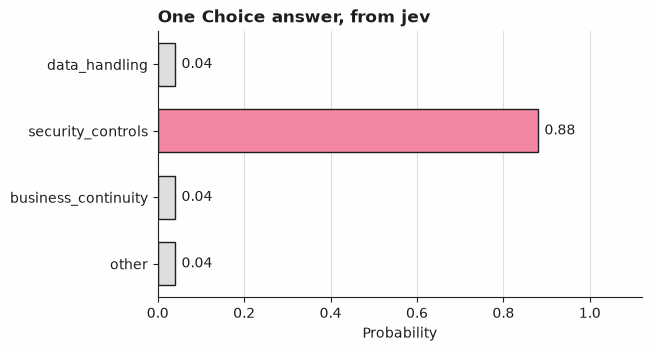

In [5]:
plot_answer_probabilities(result_a["category"], title="One Choice answer, from jev")

## The composition boundary

Request B depends on request A's own `category` answer: `helpers.needs_followup` is `False`
exactly when that answer is `other`. The boundary is visible here, not just asserted: the cell
below fetches request B for `d01` (whose `jev` category answer is not `other`) and explicitly
skips it for `d02` (whose answer is `other`) -- it never fetches and discards. Each backend
decides this from its **own** category answer, so two backends can disagree about whether a
given statement is worth a second request at all; the loop below shows what each backend, not
just `jev`, actually does for both demo statements.

In [6]:
d02 = demo["d02"]
for example in (d01, d02):
    print(f"{example.id}: {example.fields['statement'][:60]!r}...")
    example_state = helpers.build_state(example.fields)
    for name, backend in backends.items():
        category_answer = backend.decide(example_state, questions_a)["category"]
        if helpers.needs_followup(category_answer):
            specificity_answer = backend.decide(example_state, questions_b)["specificity"]
            print(
                f"  {name:14s} category={category_answer.choice:20s} "
                f"-> fetches request B, specificity score {specificity_answer.score:.2f}"
            )
        else:
            print(
                f"  {name:14s} category={category_answer.choice:20s} "
                "-> skips request B (not worth asking)"
            )

d01: 'We encrypt customer records at rest using AES-256 and review'...
  jev            category=security_controls    -> fetches request B, specificity score 2.64
  atlas-compact  category=security_controls    -> fetches request B, specificity score 2.10
  northstar-7b   category=security_controls    -> fetches request B, specificity score 1.64
d02: 'Our office coffee machine was serviced last week.'...
  jev            category=other                -> skips request B (not worth asking)
  atlas-compact  category=other                -> skips request B (not worth asking)
  northstar-7b   category=other                -> skips request B (not worth asking)


## Python's part

`helpers.triage` combines one backend's answers into one outcome, and holds whatever the model
answers: a low-confidence `category` answer goes to [`review`](../../docs/glossary.md#review);
`other` is a complete answer (CONTRIBUTING.md section 4) that clears the statement once it has
passed that same confidence gate; otherwise both `Noul` propositions pass through a two-sided
[confidence gate](../../docs/glossary.md#confidence-gate) before Python's own arithmetic -- a
fixed business cutoff, `SPECIFICITY_CUTOFF`, never calibrated from data -- decides between
`flagged` and `needs_detail`. `d03` is a resubmission (state Python keeps outside the model):
a resubmission that still lands on `review` escalates instead, because it has already failed
this gate once before.

## Calibrating each backend separately

Two thresholds are chosen per backend, on `validation` only, then frozen:

- **The `Choice` confidence threshold**, `choice_threshold`, below which a `category` answer
  goes to review whatever it names. Chosen with `select_confidence_threshold`.
- **The `Noul` gate width**, `gate_width`, for the two-sided band
  `confidence = |2p - 1| >= gate_width`. A `Noul` has no native confidence
  (docs/glossary.md#confidence), so `noul_confidence` derives one from each stored probability,
  and the gate is chosen the same way a `Choice` confidence threshold is: on validation, by
  `select_confidence_threshold`, pooling both propositions' validation answers for one backend
  into one calibration (`verifiable` and `names_control` share one gate per backend, chosen
  together).

Both use `min_coverage` as the objective (not `target_accuracy=1.0`, which would force
validation accuracy to 1.0 by construction): the lowest-risk threshold among those that still
answer at least `CHOICE_MIN_COVERAGE` (respectively `GATE_MIN_COVERAGE`) of validation. Every
value printed below is a selection step, not a reported result, and every number in this
notebook is still a pipeline check: both labels are printed on every validation line.

In [7]:
from jev_cookbook.evaluation import noul_confidence, select_confidence_threshold

CHOICE_MIN_COVERAGE = 0.80
GATE_MIN_COVERAGE = 0.80

validation = [e for e in examples if e.split == "validation"]

choice_threshold = {}
gate_width = {}
for name, backend in backends.items():
    # Request A answers all three of its questions at once, so each example is decided ONCE
    # here and every question's answer is indexed off that one result. Deciding the same state
    # again for `verifiable` and `names_control` would be two more billed requests, live, for
    # answers already in hand.
    answers_a = [backend.decide(helpers.build_state(e.fields), questions_a) for e in validation]
    cat_answers = [a["category"] for a in answers_a]
    cat_gold = [labels[e.id]["category"] for e in validation]
    correct = [a.choice == g for a, g in zip(cat_answers, cat_gold, strict=True)]
    confidence = [a.confidence for a in cat_answers]
    choice_threshold[name] = select_confidence_threshold(
        correct, confidence, min_coverage=CHOICE_MIN_COVERAGE
    )

    pooled_correct, pooled_conf = [], []
    for prop in ("verifiable", "names_control"):
        prop_answers = [a[prop] for a in answers_a]
        prop_gold = [labels[e.id][prop] for e in validation]
        probs = [a.noul for a in prop_answers]
        pooled_correct += [(p >= 0.5) == g for p, g in zip(probs, prop_gold, strict=True)]
        pooled_conf += noul_confidence(probs)
    gate_width[name] = select_confidence_threshold(
        pooled_correct, pooled_conf, min_coverage=GATE_MIN_COVERAGE
    )

    print(
        f"{name:14s} choice_threshold={choice_threshold[name]:.4f}{selection}{check}  "
        f"gate_width={gate_width[name]:.4f}{selection}{check}"
    )

jev            choice_threshold=0.7067 (a selection step, not a reported result) (a pipeline check, not a Jev result)  gate_width=0.4800 (a selection step, not a reported result) (a pipeline check, not a Jev result)
atlas-compact  choice_threshold=0.4400 (a selection step, not a reported result) (a pipeline check, not a Jev result)  gate_width=0.1200 (a selection step, not a reported result) (a pipeline check, not a Jev result)
northstar-7b   choice_threshold=0.2800 (a selection step, not a reported result) (a pipeline check, not a Jev result)  gate_width=0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)


In [8]:
d03 = demo["d03"]
print(f"d03 ({d03.fields['resubmission']=}): {d03.fields['statement']}")
for name, backend in backends.items():
    example_state = helpers.build_state(d03.fields)
    answers_a = backend.decide(example_state, questions_a)  # one request, three answers
    category_answer = answers_a["category"]
    verifiable_answer = answers_a["verifiable"]
    names_control_answer = answers_a["names_control"]
    specificity_answer = None
    if helpers.needs_followup(category_answer):
        specificity_answer = backend.decide(example_state, questions_b)["specificity"]
    routing = helpers.triage(
        d03.id,
        category_answer,
        verifiable_answer,
        names_control_answer,
        specificity_answer,
        choice_threshold=choice_threshold[name],
        gate_width=gate_width[name],
        resubmission=d03.fields["resubmission"],
    )
    print(
        f"  {name:14s} category={category_answer.choice:14s} "
        f"confidence={category_answer.confidence:.2f} -> {routing.outcome} ({routing.reason})"
    )

d03 (d03.fields['resubmission']=True): We follow applicable data protection laws, as we did in our last review.
  jev            category=data_handling  confidence=0.20 -> escalate_review (resubmission still below the threshold)
  atlas-compact  category=data_handling  confidence=0.27 -> escalate_review (resubmission still below the threshold)
  northstar-7b   category=data_handling  confidence=0.17 -> escalate_review (resubmission still below the threshold)


## Evaluation

Every number below is computed the same way for every backend, through the same functions, and
none is compared against another: this section reports what each backend's own frozen
calibration does, backend by backend, never a ranking. `jev_cookbook.evaluation.accuracy` scores
the `category` choice against the [gold label](../../docs/glossary.md#gold-label) -- the
example's recorded correct answer, from `fixtures/labels.jsonl`, used only to score an answer
after the fact and never shown to any backend; `evaluate_selective` applies the frozen
`choice_threshold`; `evaluate_outcomes` reports the composed `triage` outcome, since its review
branch is more than a confidence gate (CONTRIBUTING.md section 4: the explicit `other` fallback
and the two-sided Noul gate are both unconditional branches of their own, not expressible as one
confidence cut). `test` is read once, after every threshold above is frozen.

In [9]:
from jev_cookbook.evaluation import accuracy, evaluate_outcomes, evaluate_selective

test = [e for e in examples if e.split == "test"]


def decide_row(backend, example):
    state = helpers.build_state(example.fields)
    answers = backend.decide(state, questions_a)
    specificity_answer = None
    if helpers.needs_followup(answers["category"]):
        specificity_answer = backend.decide(state, questions_b)["specificity"]
    return answers, specificity_answer


def report_backend(name, backend, split_examples, label, check):
    """One backend's own rows of one split's table. ``check`` is THAT backend's own mode
    label, not jev's: these numbers came from this backend and are labelled from its mode."""
    rows = [decide_row(backend, e) for e in split_examples]
    cat_answers = [r[0]["category"] for r in rows]
    cat_gold = [labels[e.id]["category"] for e in split_examples]
    cat_acc = accuracy(cat_gold, cat_answers)
    sel = evaluate_selective(
        [a.choice == g for a, g in zip(cat_answers, cat_gold, strict=True)],
        [a.confidence for a in cat_answers],
        choice_threshold[name],
    )
    accepted, correct_composed, outcomes = [], [], []
    for (answers, specificity_answer), e in zip(rows, split_examples, strict=True):
        routing = helpers.triage(
            e.id,
            answers["category"],
            answers["verifiable"],
            answers["names_control"],
            specificity_answer,
            choice_threshold=choice_threshold[name],
            gate_width=gate_width[name],
            resubmission=e.fields["resubmission"],
        )
        outcomes.append(routing.outcome)
        is_review = routing.outcome in (helpers.REVIEW, helpers.ESCALATE_REVIEW)
        accepted.append(not is_review)
        correct_composed.append(answers["category"].choice == labels[e.id]["category"])
    composed = evaluate_outcomes(accepted, correct_composed)
    print(
        f"  {name:14s} category accuracy={cat_acc:.4f}{label}{check}  "
        f"category coverage={sel.coverage:.4f}{label}{check} risk={sel.risk:.4f}{label}{check}"
    )
    print(
        f"  {'':14s} composed coverage={composed.coverage:.4f}{label}{check} "
        f"composed risk={composed.risk:.4f}{label}{check}"
    )
    counts = {o: outcomes.count(o) for o in sorted(set(outcomes))}
    print(f"  {'':14s} outcomes: {counts}{check}")


check = harness_check  # the split header below covers all three backends at once
for split_name, split_examples, label in (
    ("validation", validation, selection),
    ("test", test, ""),
):
    print(f"--- {split_name}, {len(split_examples)} examples{label}{check} ---")
    for name, backend in backends.items():
        report_backend(name, backend, split_examples, label, check_by_backend[name])

--- validation, 10 examples (a selection step, not a reported result) (a pipeline check, not a Jev result) ---
  jev            category accuracy=1.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)  category coverage=1.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result) risk=0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
                 composed coverage=1.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result) composed risk=0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
                 outcomes: {'cleared': 7, 'flagged': 3} (a pipeline check, not a Jev result)
  atlas-compact  category accuracy=1.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)  category coverage=1.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result) risk=0.0000 (a selection step, n

### One backend's confusion matrix

A confusion matrix is a harness check, not a comparison: this one is `jev`'s own `category`
predictions on `test`, read on its own, to see which categories it confuses -- never set beside
the other two backends' matrices to imply a ranking.

jev, test confusion matrix, gold rows by predicted columns (a pipeline check, not a Jev result):
  predicted ->                    data_handling    security_controls  business_continuity                other (a pipeline check, not a Jev result)
  gold data_handling                          3                    0                    0                    0 (a pipeline check, not a Jev result)
  gold security_controls                      1                    2                    0                    0 (a pipeline check, not a Jev result)
  gold business_continuity                    0                    0                    2                    0 (a pipeline check, not a Jev result)
  gold other                                  0                    0                    0                    2 (a pipeline check, not a Jev result)


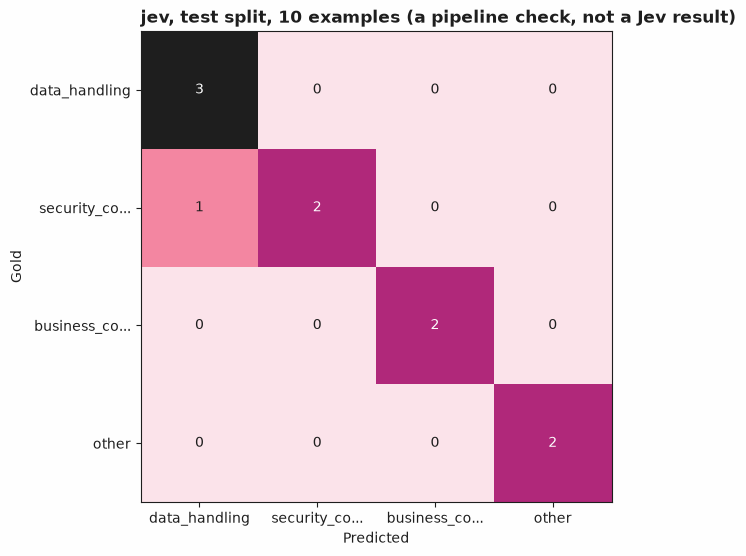

In [10]:
from jev_cookbook.evaluation import confusion_matrix

check = check_by_backend["jev"]  # this cell reports jev alone, so it carries jev's own label

jev_test_cat = [decide_row(backends["jev"], e)[0]["category"] for e in test]
jev_test_gold = [labels[e.id]["category"] for e in test]
matrix = confusion_matrix(jev_test_gold, jev_test_cat, labels=list(helpers.CATEGORIES))
width = max(len(label) for label in matrix.labels)
leader_width = max(width + len("gold "), len("predicted ->"))
header = "  ".join(f"{label:>{width}s}" for label in matrix.labels)
print(f"jev, test confusion matrix, gold rows by predicted columns{check}:")
print(f"  {'predicted ->':<{leader_width}s}  {header}{check}")
for gold_label, row in zip(matrix.labels, matrix.matrix.tolist(), strict=True):
    counts = "  ".join(f"{c:{width}d}" for c in row)
    leader = f"gold {gold_label:<{width}s}"
    print(f"  {leader:<{leader_width}s}  {counts}{check}")
plot_confusion_matrix(matrix, title=f"jev, test split, {len(test)} examples{check}")

## Where the Noul gate bends

`confidence = |2p - 1|` is symmetric about 0.5, so the gate accepts on either side: a statement
is confidently true when `p >= (1 + g) / 2`, confidently false when `p <= (1 - g) / 2`, and sent
to review otherwise. Whether a given gate width `g` actually changes anything is not derivable
from `g` and a business threshold alone -- it depends on how the rule wires the gate into its
own composition, so it is measured here directly, against `helpers.triage`'s own composed
outcome, over a 101-point grid on `validation` (never `test`, which is read only once, above,
with the frozen width already applied).

The grid moves a Python gate, not a request: every row is decided once and the same answers are
re-composed at all 101 points, so the sweep costs one pass of requests rather than 101 of them
(see "What a live run of this notebook would cost").

In [11]:
def composed_outcomes(rows, gate_width_value):
    """Re-compose already-decided answers at one gate width. The sweep moves a Python gate, not
    a request, so each row is decided once and re-composed at all 101 points: a live run pays
    for the decisions, never for the grid."""
    outcomes = []
    for (answers, specificity_answer), e in zip(rows, validation, strict=True):
        routing = helpers.triage(
            e.id,
            answers["category"],
            answers["verifiable"],
            answers["names_control"],
            specificity_answer,
            choice_threshold=0.0,  # isolate the Noul gate: never review on category confidence here
            gate_width=gate_width_value,
            resubmission=e.fields["resubmission"],
        )
        outcomes.append(routing.outcome)
    return outcomes


def sweep_backend(name, backend, grid, check):
    """One backend's sweep row; ``check`` is that backend's own mode label."""
    rows = [decide_row(backend, e) for e in validation]
    baseline = composed_outcomes(rows, 0.0)
    first_bend = None
    changed_at_1 = 0
    for g in grid:
        current = composed_outcomes(rows, g)
        changed = sum(1 for a, b in zip(baseline, current, strict=True) if a != b)
        if changed and first_bend is None:
            first_bend = g
        if g == 1.0:
            changed_at_1 = changed
    print(
        f"  {name:14s} calibrated gate_width={gate_width[name]:.4f}{selection}{check}  "
        f"first bend at g={first_bend}{selection}{check}  "
        f"changed outcomes at g=1.0: {changed_at_1} of {len(validation)}{selection}{check}"
    )


check = harness_check  # the header below covers all three backends at once
grid = [i / 100 for i in range(101)]
print(f"gate width sweep on validation{selection}{check}, {len(grid)} points:")
for name, backend in backends.items():
    sweep_backend(name, backend, grid, check_by_backend[name])

gate width sweep on validation (a selection step, not a reported result) (a pipeline check, not a Jev result), 101 points:
  jev            calibrated gate_width=0.4800 (a selection step, not a reported result) (a pipeline check, not a Jev result)  first bend at g=0.49 (a selection step, not a reported result) (a pipeline check, not a Jev result)  changed outcomes at g=1.0: 8 of 10 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  atlas-compact  calibrated gate_width=0.1200 (a selection step, not a reported result) (a pipeline check, not a Jev result)  first bend at g=0.13 (a selection step, not a reported result) (a pipeline check, not a Jev result)  changed outcomes at g=1.0: 8 of 10 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  northstar-7b   calibrated gate_width=0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)  first bend at g=0.01 (a selection step, not a reported result) (a pip

## Leak check

The fixtures are synthetic and hand-written, so before reading any number above as telling us
anything about the harness's wiring, the cheapest surface features that could recover a gold
label without reading the statement at all are swept -- at **every** granularity this recipe
has a label for, including the ones no reported number is computed against: each `Noul`
proposition, each `Choice` category option, the `Score` cutoff, each individual `Score` level,
and the composed outcome.

The feature family is computed from the statements rather than hand-picked, and what gets
reported per granularity is the **extremum**: the best feature and what it scored. Two chosen
probes can only say "these two did not leak", which is a demonstration; the best of every word,
word pair, length cutoff and character class in the fixtures, in both polarities, is a
measurement. The signature of a leak is a feature that is perfect with no false positives on
`validation`, fires on at least one positive there (a feature that never fires scores 1.0
against an all-negative label and has measured nothing), and stays perfect on `test` unchanged.

The sweep finds one such feature, at `specificity==3`: the three gold level-3 statements were
written to a shared template and share a word no other scored statement has, so the generation
template wrote the level into the prose. It reaches nothing this notebook reports --
`helpers.triage` only ever asks `specificity >= SPECIFICITY_CUTOFF`, and the sweep's
`specificity>=cutoff` row shows no clean feature at that granularity -- and the cell prints that
split (leaking granularities a reported number is computed against, versus leaking granularities
nothing above reads) rather than asking you to take it on trust. A probe against the composed
outcome cannot stand in for the per-proposition probes either: one proposition's own errors keep
the composed accuracy below 1.0 by arithmetic, so each granularity is swept on its own.


In [12]:
import re

WORD = re.compile(r"[a-z0-9]+")


def fire_table(vocabulary_examples, split_examples):
    """``{feature name: [whether it fires on each example of the split]}``.

    The family is computed, not chosen: every word and adjacent word pair in the statements,
    every word-count and character-length cutoff they take, three character classes, and all of
    those negated. The vocabulary comes from both splits together, so a feature that is clean on
    `validation` can be looked up on `test` instead of silently not existing there.
    """
    vocab_tokens = [WORD.findall(e.fields["statement"].lower()) for e in vocabulary_examples]
    texts = [e.fields["statement"] for e in split_examples]
    tokens = [WORD.findall(t.lower()) for t in texts]
    joined = [" ".join(ts) for ts in tokens]
    table = {}
    for word in sorted({t for ts in vocab_tokens for t in ts}):
        table[f"word:{word}"] = [word in ts for ts in tokens]
    for bigram in sorted(
        {f"{a} {b}" for ts in vocab_tokens for a, b in zip(ts, ts[1:], strict=False)}
    ):
        table[f"bigram:{bigram}"] = [bigram in j for j in joined]
    for cutoff in sorted({len(ts) for ts in vocab_tokens}):
        table[f"words>={cutoff}"] = [len(ts) >= cutoff for ts in tokens]
    for cutoff in sorted({len(e.fields["statement"]) for e in vocabulary_examples}):
        table[f"chars>={cutoff}"] = [len(t) >= cutoff for t in texts]
    table["has_digit"] = [bool(re.search(r"[0-9]", t)) for t in texts]
    table["has_audit_word"] = [
        bool(re.search(r"audit|review(ed)?|ISO|SOC", t, re.IGNORECASE)) for t in texts
    ]
    table["has_acronym"] = [bool(re.search(r"[A-Z]{2,}", t)) for t in texts]
    for name in list(table):  # both polarities: an absence leaks as easily as a presence
        table[f"not:{name}"] = [not fires for fires in table[name]]
    return table


def jev_flagged(example):
    """Whether jev's own composed outcome for one example is FLAGGED -- its own outcome, never
    a gold label."""
    answers, specificity_answer = decide_row(backends["jev"], example)
    routing = helpers.triage(
        example.id,
        answers["category"],
        answers["verifiable"],
        answers["names_control"],
        specificity_answer,
        choice_threshold=choice_threshold["jev"],
        gate_width=gate_width["jev"],
        resubmission=example.fields["resubmission"],
    )
    return routing.outcome == helpers.FLAGGED


def gold_vectors(split_examples):
    """``{granularity: [gold value per example, or None where the label does not apply]}`` --
    every label this recipe has, at every option and every level, not only the granularities a
    reported number is computed against."""
    vectors = {
        "verifiable": [labels[e.id].get("verifiable") for e in split_examples],
        "names_control": [labels[e.id].get("names_control") for e in split_examples],
        "specificity>=cutoff": [
            None
            if labels[e.id].get("specificity") is None
            else labels[e.id]["specificity"] >= helpers.SPECIFICITY_CUTOFF
            for e in split_examples
        ],
    }
    for category in helpers.CATEGORIES:
        vectors[f"category=={category}"] = [
            labels[e.id]["category"] == category for e in split_examples
        ]
    for level in range(len(helpers.SPECIFICITY_LEVELS)):
        vectors[f"specificity=={level}"] = [
            None
            if labels[e.id].get("specificity") is None
            else labels[e.id]["specificity"] == level
            for e in split_examples
        ]
    vectors["composed FLAGGED (jev)"] = [jev_flagged(e) for e in split_examples]
    return vectors


def probe_score(fires, golds):
    """``(fires_on_positives, labelled_rows, fp, fn, accuracy)`` for one feature, one label."""
    pairs = [(f, g) for f, g in zip(fires, golds, strict=True) if g is not None]
    tp = sum(1 for f, g in pairs if f and g)
    tn = sum(1 for f, g in pairs if not f and not g)
    fp = sum(1 for f, g in pairs if f and not g)
    fn = sum(1 for f, g in pairs if not f and g)
    acc = (tp + tn) / len(pairs) if pairs else float("nan")
    return tp, len(pairs), fp, fn, acc


def is_clean(score):
    """A leak's signature on one split: perfect, and firing on at least one positive."""
    tp, labelled, fp, fn, _ = score
    return labelled > 0 and tp > 0 and fp == 0 and fn == 0


check = PIPELINE_CHECK  # labels.jsonl is hand-written in every mode: never a recorded result
validation_table = fire_table(validation + test, validation)
test_table = fire_table(validation + test, test)
validation_gold = gold_vectors(validation)
test_gold = gold_vectors(test)
leaking = {}

print(
    f"{len(validation_table)} surface features (both polarities) over "
    f"{len(validation_gold)} granularities{check}; best feature per granularity, ties by name:"
)
for granularity, golds in validation_gold.items():
    scores = {name: probe_score(fires, golds) for name, fires in validation_table.items()}
    best_name = None
    for name in sorted(scores):
        if best_name is None or scores[name][4] > scores[best_name][4]:
            best_name = name
    tp, labelled, fp, fn, acc = scores[best_name]
    transfers = sorted(
        name
        for name, score in scores.items()
        if is_clean(score) and is_clean(probe_score(test_table[name], test_gold[granularity]))
    )
    shown = ", ".join(transfers[:3]) + (
        f", +{len(transfers) - 3} more" if len(transfers) > 3 else ""
    )
    leaking[granularity] = transfers
    print(
        f"  {granularity:30s} best={best_name:22s} rows={labelled:2d} fires_on_positives={tp:2d} "
        f"fp={fp} fn={fn} accuracy={acc:.4f}{check}"
    )
    print(
        f"  {'':30s} clean on validation: {sum(1 for s in scores.values() if is_clean(s)):4d}; "
        f"clean on BOTH splits: {shown or 'none'}{check}"
    )

reported = [g for g in validation_gold if not g.startswith("specificity==")]
print(f"\nleaks (clean on both splits), by whether anything above is computed against them{check}:")
print(
    f"  of the {len(reported)} granularities a reported number is computed against: "
    f"{sorted(g for g in reported if leaking[g]) or 'none'}"
)
print(
    f"  of the granularities nothing above reads (helpers.triage asks only "
    f"specificity >= {helpers.SPECIFICITY_CUTOFF}): "
    f"{sorted(g for g in validation_gold if leaking[g] and g not in reported) or 'none'}"
)

822 surface features (both polarities) over 12 granularities (a pipeline check, not a Jev result); best feature per granularity, ties by name:
  verifiable                     best=word:an                rows=10 fires_on_positives= 2 fp=0 fn=2 accuracy=0.8000 (a pipeline check, not a Jev result)
                                 clean on validation:    0; clean on BOTH splits: none (a pipeline check, not a Jev result)
  names_control                  best=chars>=73              rows=10 fires_on_positives= 4 fp=1 fn=0 accuracy=0.9000 (a pipeline check, not a Jev result)
                                 clean on validation:    0; clean on BOTH splits: none (a pipeline check, not a Jev result)
  specificity>=cutoff            best=word:an                rows= 8 fires_on_positives= 2 fp=0 fn=1 accuracy=0.8750 (a pipeline check, not a Jev result)
                                 clean on validation:    0; clean on BOTH splits: none (a pipeline check, not a Jev result)
  category==data_handli

## What a live run of this notebook would cost

Two different quantities both get called "requests", and sizing a budget from the wrong one is
how a live run stops halfway through with `BudgetExceeded`:

- **Distinct requests** -- distinct `(state, questions)` pairs, keyed by `replay_key`. This is
  what `fixtures/responses.json` holds one entry per, and what a replay run answers from a dict.
- **Forwarded `decide()` calls** -- what a live backend bills. `LiveBackend.decide` spends
  budget on every attempt it makes and caches nothing, so a notebook that decides the same
  state again to fill a second table pays again for an answer it already had.

Every backend here is wrapped in `helpers.MemoisingBackend`, which forwards each distinct
request exactly once, so for this notebook the two quantities are equal. That equality is a
property of the wrapper, not something the assertion below defends: a cell that re-decides a
state fails nothing, it simply costs nothing, because the memo absorbs the repeat -- and the
printed `repeats` count is what makes those repeats visible, each one a request a live backend
would have billed, so forwarded calls plus repeats is what this notebook would have cost
without the wrapper. The conjunct that pins the number itself is `jev.calls == stored["jev"]`,
which goes false the moment a cell asks for a request the committed fixtures do not hold.

Even an exact call count is a **floor** on what a live run bills. `jev_cookbook.live`'s budget
error says it plainly -- "retries and timed-out requests count" -- so a retried or timed-out
attempt bills on top of the counts below. The bound the cell asserts is the one to size a budget
from: at least one request per example, at most two (request A always, request B at most once),
whichever rows a live `category` answer happens to send to request B.


In [13]:
import json

jev = backends["jev"]
check = check_by_backend["jev"]  # this cell reports jev's own requests
stored = {
    name: len(json.loads(responses_path(tag=tag).read_text(encoding="utf-8")))
    for name, tag in BACKEND_TAGS.items()
}

print(f"jev, this run{check}:")
print(f"  distinct requests asked (one per replay key): {jev.requests}")
print(f"  decide() calls forwarded to the backend:      {jev.calls}")
print(f"  repeats answered from the memo instead:       {jev.repeats}")
print(f"  stored responses in fixtures/responses.json:  {stored['jev']}")
print(
    "A live run bills one request per forwarded call, and each retried or timed-out attempt "
    "counts on\ntop of that, so the forwarded count is a floor. atlas-compact and northstar-7b "
    "are never called\nlive, whatever the environment says, so they add nothing to a live budget."
)

assert jev.calls == jev.requests, (
    f"every distinct request must be forwarded exactly once: {jev.calls} calls for "
    f"{jev.requests} distinct requests"
)
# One request A per example always, request B at most once more: the budget a live run needs
# lies in this range whichever rows its own category answers send to request B.
assert len(examples) <= jev.calls <= 2 * len(examples), (
    f"{jev.calls} forwarded calls is outside the {len(examples)}..{2 * len(examples)} a "
    "notebook asking request A once and request B at most once per example can make"
)
if offline:
    # Replaying the committed fixtures, the gate follows the stored design exactly, so the
    # count is not just bounded but equal to the number of stored responses.
    assert jev.calls == stored["jev"], (
        f"expected one forwarded call per stored response ({stored['jev']}); made {jev.calls}"
    )
    assert set(stored.values()) == {stored["jev"]}, (
        f"every backend must store a response for the same requests: {stored}"
    )

jev, this run (a pipeline check, not a Jev result):
  distinct requests asked (one per replay key): 41
  decide() calls forwarded to the backend:      41
  repeats answered from the memo instead:       83
  stored responses in fixtures/responses.json:  41
A live run bills one request per forwarded call, and each retried or timed-out attempt counts on
top of that, so the forwarded count is a floor. atlas-compact and northstar-7b are never called
live, whatever the environment says, so they add nothing to a live budget.


## What was and was not measured

No live run has been recorded for this recipe: `JEV_COOKBOOK_LIVE` was unset for every number
above, so every backend answered from stored, synthetic fixtures. The cell below states that
plainly and prints N -- the number of scored examples -- in both branches, as every recipe's
version of this cell does.

**The harness ran and produced tables; none of those cells is evidence about any model's
quality, latency, or cost.** Jev's own quality, latency, and cost are not stated anywhere above,
and neither are `atlas-compact`'s or `northstar-7b`'s: fabricated names describing a fabricated
decision adapter, used only to exercise the same `Backend` protocol offline. No accuracy number
above ranks the three backends; each is a pipeline check for the backend it names, nothing more.

In [14]:
check = check_by_backend["jev"]  # this cell discloses jev's provenance, so it uses jev's label
if offline:
    print(
        f"Provenance: {backends['jev'].mode}. Not measured live: a pipeline check, not a Jev result."
    )
    print(f"N: {len(validation)} validation and {len(test)} test examples{check}")
else:
    dates = ", ".join(getattr(backends["jev"], "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backends['jev'].mode}, model {backends['jev'].model}")
    print(f"Captured: {dates}")
    print(f"N: {len(validation)} validation and {len(test)} test examples")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 10 validation and 10 test examples (a pipeline check, not a Jev result)


## Next steps

- Change one Score level's wording in `helpers.py` and run `pytest recipes/50-model-comparison-and-calibration`
  or this notebook: the stored keys no longer match request B's question, so replay misses
  instead of guessing.
- Add a fourth backend by writing `fixtures/responses-<tag>.json` for the same replay keys and
  adding it to `BACKEND_TAGS` -- nothing else in the harness changes, because every backend
  answers through the same `Backend` protocol.
- Record a real live run (see this recipe's README, "Switch to live") and watch the `jev`
  rows' label change from `(a pipeline check, not a Jev result)` to `(recorded)` -- while the
  `atlas-compact` and `northstar-7b` rows keep the pipeline-check label, because this recipe
  never calls either of them live, so their numbers stay synthetic in every mode. Every label
  is derived from the mode of the backend that produced the number, not from `jev`'s.
- Neighbouring recipes: [`23-pairwise-answer-evaluation`](../23-pairwise-answer-evaluation/),
  which this recipe's evaluation patterns build on, and
  [`38-abstention-and-review-queues`](../38-abstention-and-review-queues/), whose review-queue
  pattern this recipe's confidence gates follow.